# 05–Ablation and SHAP(Part B)
The scripts in `src/` are executed, and the results are shown. The domain-disjoint split and XGBoost, which tied with Random Forest as the best model in Part A, are used throughout. As a result, the test URLs originate from domains that the model was not exposed to during training.

In [1]:
%cd ..
import pandas as pd
from IPython.display import Image, display

/content/PhishGuard


## 1.Feature-group ablation
Here, I remove one set of features at a time (character ratios, domain/TLD, and leak-suspect ones), then all three at once, and observe how much F1 drops in comparison to using each feature.

          removed      f1     fnr  f1_drop
0        baseline  0.9998  0.0003   0.0000
1  - leak_suspect  0.9961  0.0061   0.0038
2    - domain/TLD  0.9998  0.0003   0.0000
3    - char_ratio  0.9998  0.0003   0.0000
4  - all together  0.9911  0.0111   0.0087


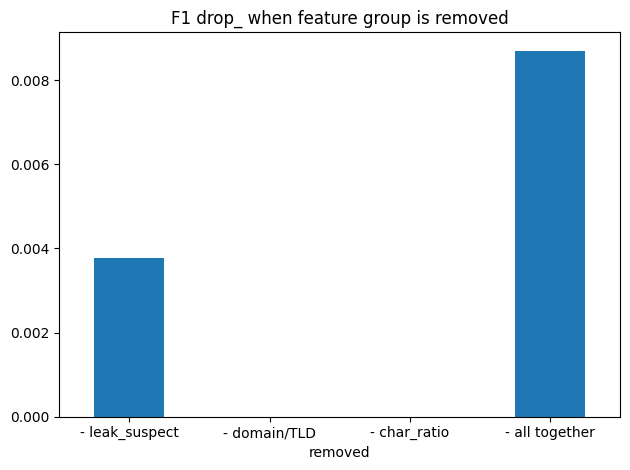

In [2]:
%run -m src.ablation

In [3]:
result = pd.read_csv("results/ablation.csv")
result[["removed", "precision", "recall", "f1", "fnr", "f1_drop"]].round(4)

,removed,precision,recall,f1,fnr,f1_drop
0,baseline,1.0000,0.9997,0.9998,0.0003,0.0000
1,- leak_suspect,0.9983,0.9939,0.9961,0.0061,0.0038
2,- domain/TLD,1.0000,0.9997,0.9998,0.0003,0.0000
3,- char_ratio,1.0000,0.9997,0.9998,0.0003,0.0000
4,- all together,0.9934,0.9889,0.9911,0.0111,0.0087


- On its own, just the leak-suspect group is important. Without it, the miss rate (FNR) increases by around 20 times, from 0.0003 to 0.0061, and F1 rises from 0.9998 to 0.9961.
- Eliminating the character-ratio or domain/TLD attributes alone has no effect. The model just relies on the other features since they contain the same information.
- F1 is remains 0.991 even after the removal of all three categories.
That doesn't seem like a strong generalisation to me. URL length and special character counts are sufficient to distinguish the classes because every legitimate URL in our dataset is a simple `https://www.<domain>` homepage.

## 2.Final model
This is XGBoost trained without 'URLSimilarityIndex', 'URLCharProb', or 'TLDLegitimateProb'. It is saved as'models/final_model'.joblib' so that the Streamlit app can access it.

In [4]:
%run -m src.final_model

{'precision': 0.9994789495623176, 'recall': 0.9945559184943226, 'f1': 0.9970113568439928, 'macro_f1': 0.9974354928611261, 'fnr': np.float64(0.005444081505677399), 'pr_auc': np.float64(0.9991815851596845), 'roc_auc': np.float64(0.9990531041078599), 'tn': np.int64(26807), 'fp': np.int64(10), 'fn': np.int64(105), 'tp': np.int64(19182)}


**Result:** On the domain-disjoint test set, the final model achieves an F1 of around 0.997 and a FNR of about 0.005. There were 105 missed phishing URLs and 10 false alerts out of 46,104 test URLs.

## 3. SHAP explanations
SHAP displays how much each attribute influenced a prediction toward phishing (right) or legitimacy (left). I begin by analysing the worldwide importance of 5,000 test URLs, followed by three unique URLs: one phishing URL caught by the model, one it missed, and one legitimate URL.

In [5]:
%run -m src.explain

caught     p=0.9997  https://liuy-9a930.web.app/


missed     p=0.0246  https://www.ioginunlcovlabcp.com/


legitimate p=0.0026  https://www.nerdscandy.com


### Global importance

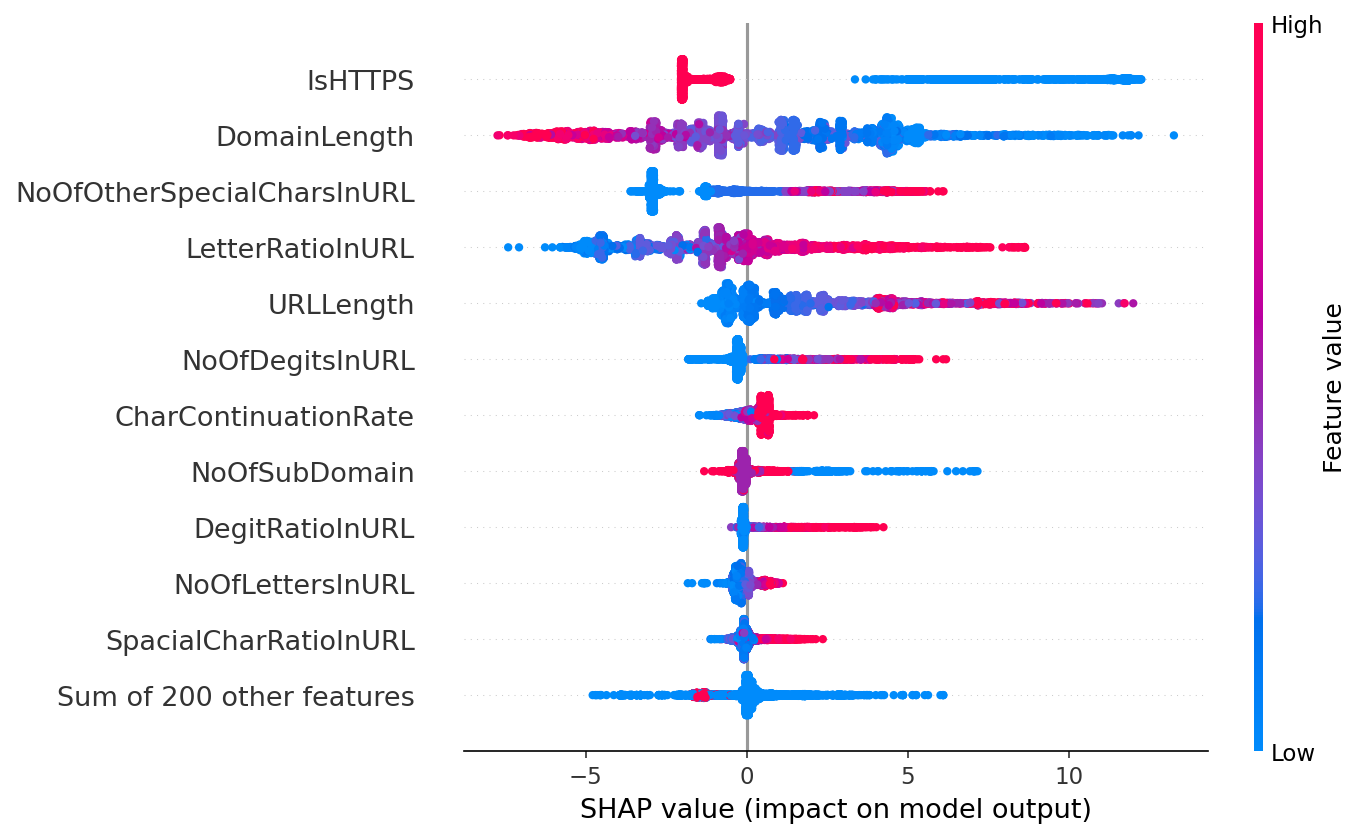

In [6]:
display(Image("results/figures/shap_global.png"))

The top features are 'IsHTTPS'  (no HTTPS pushes toward phishing) and 'DomainLength'  (short domains push toward phishing), followed by the amount of special characters and URL length, both of which are higher for phishing links.

### Single-URL explanations

caught


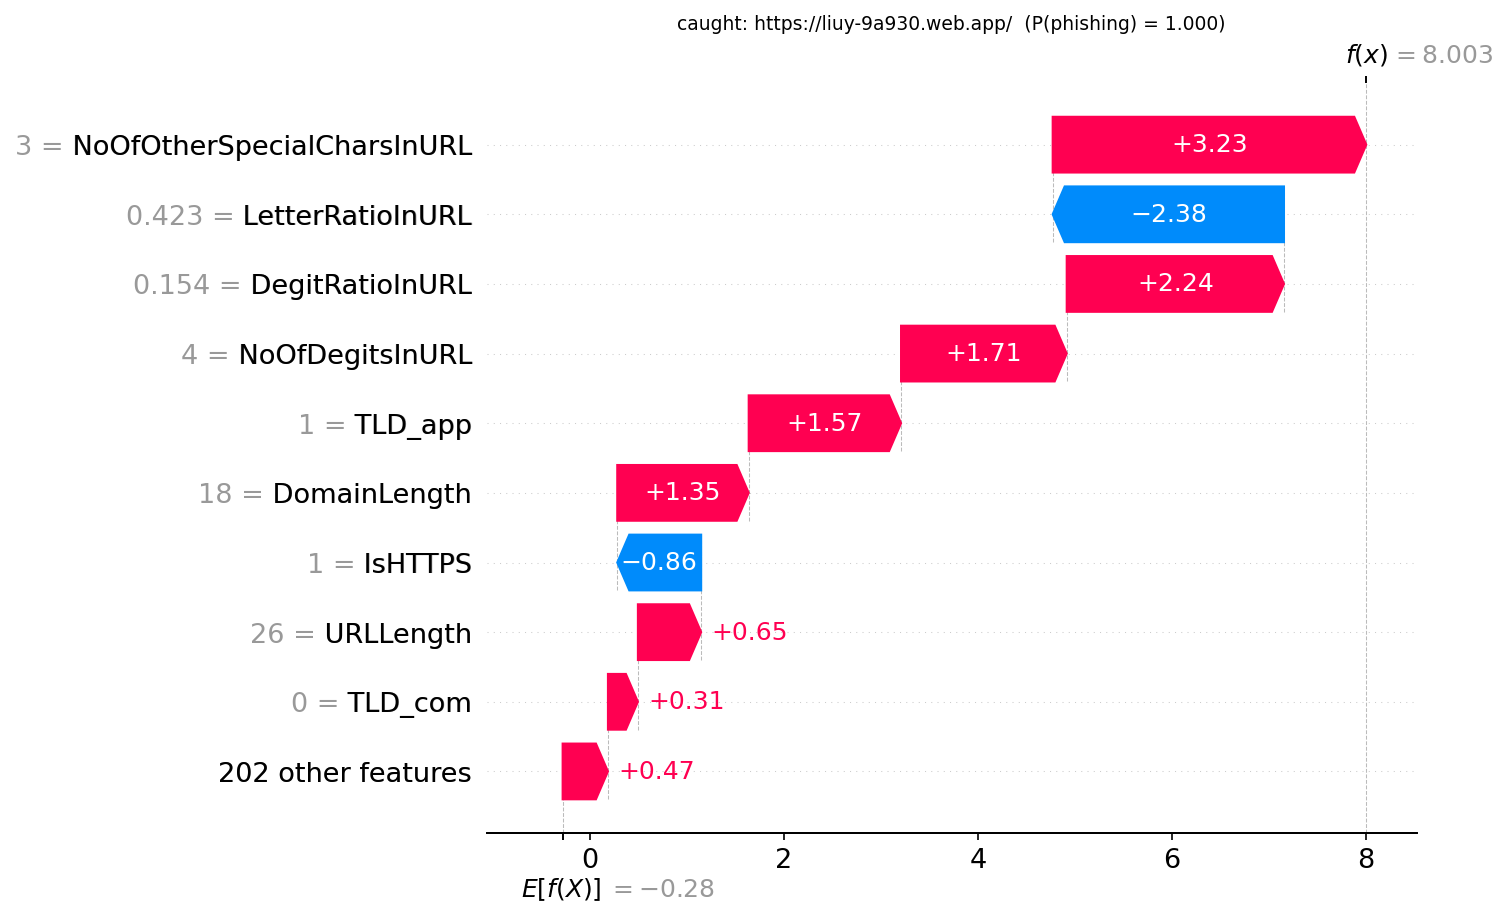

missed


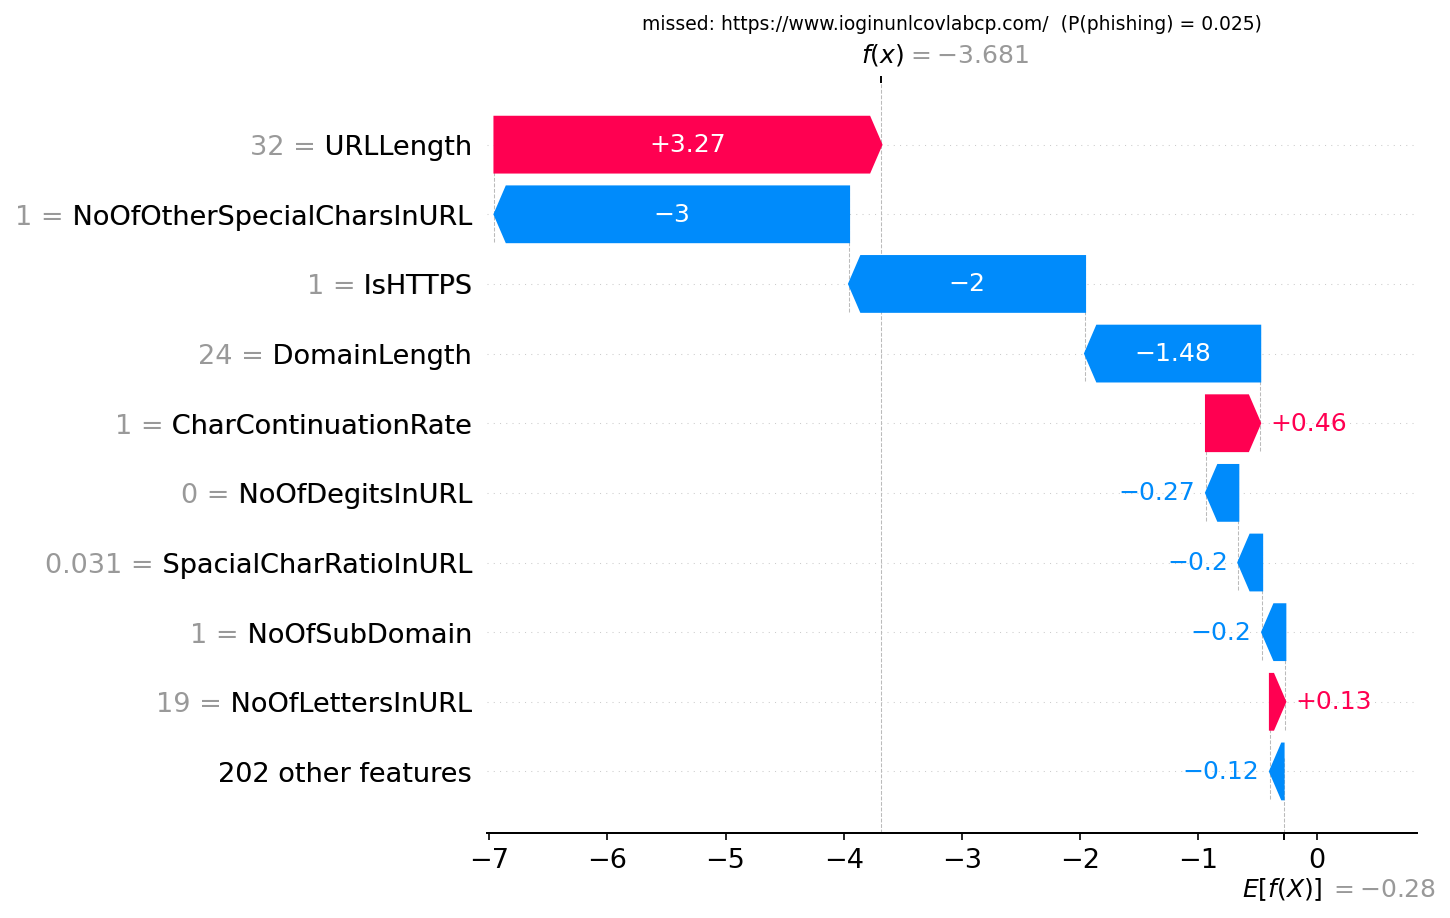

legitimate


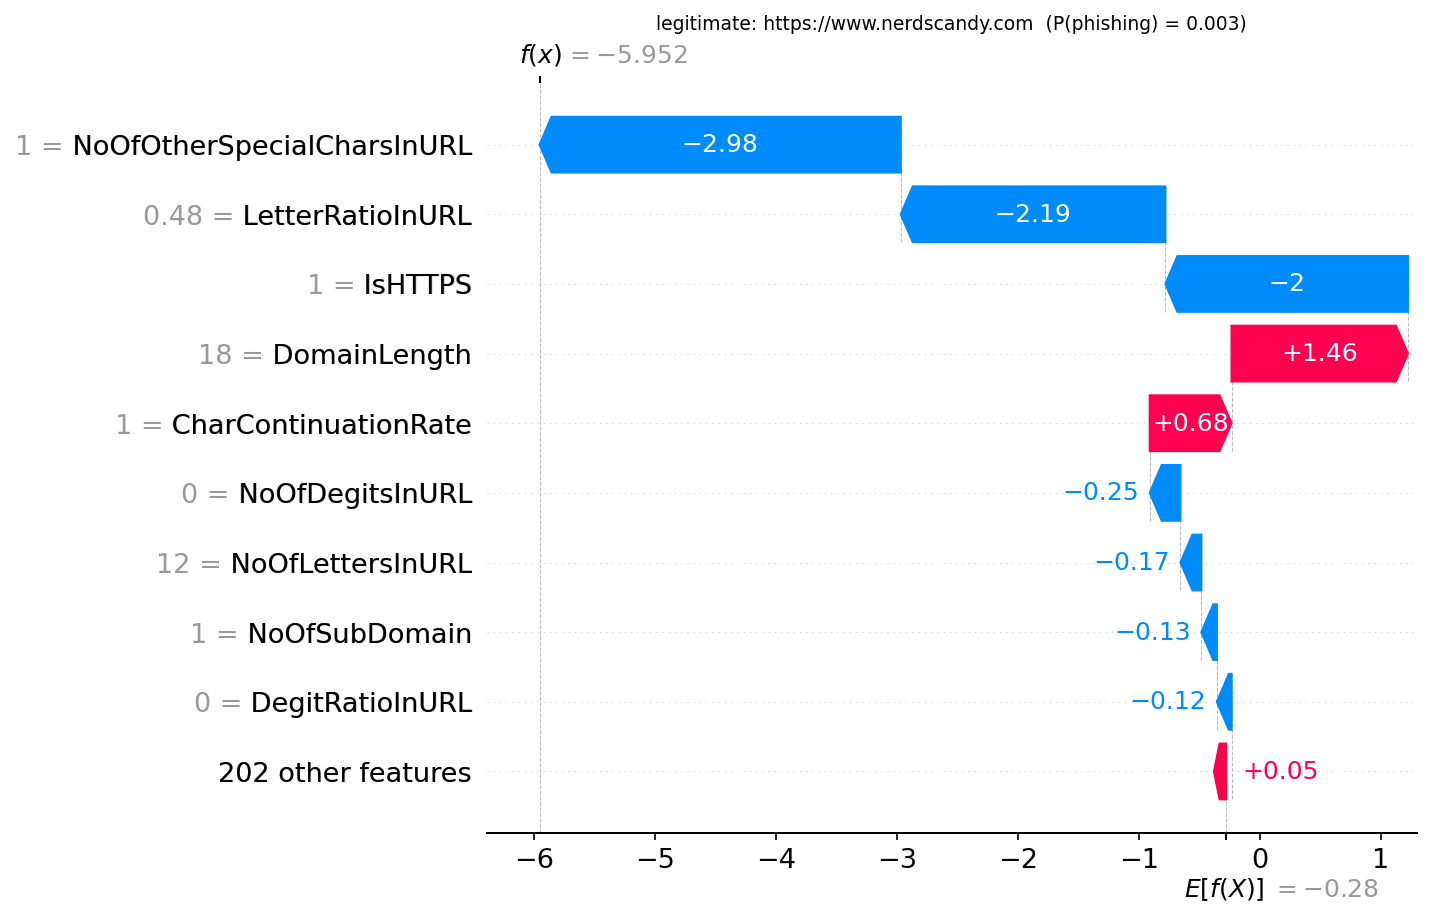

In [7]:
for case_ in ["caught", "missed", "legitimate"]:
    print(case_)
    display(Image(f"results/figures/shap_{case_}.png"))

- **Caught:** a phishing site on a free hosting domain ('web.app'). The URL's structure lends itself to phishing attempts.
- **Missed:** a simple 'https://www.<domain>' homepage. Its URL length suggests phishing, although HTTPS, a single unique character, and a standard domain length outweigh this. To the model, it appears to be an ordinary legitimate homepage.
- **Legitimate:** HTTPS, a short URL, and a few special characters all point toward legitimacy.

## Conclusion
- The leak-suspect features explain the majority of the near-perfect ratings in Part A.
- Without them, the model performs admirably, but this is due in part to the dataset's design, as all legitimate URLs are homepages.
- Phishing hosted on aesthetically pleasing HTTPS homepages is the largest vulnerability. It would take more than just the URL to catch those, such as page content or domain age.